# Compressing ERA5 500 hPa Geopotential Height with a Vision Transformer Autoencoder

**Question:** how much can we compress daily z500 maps over the North Atlantic / Europe, and does a Vision Transformer autoencoder (ViT-AE) beat the optimal linear method (PCA)?

| | Method | What it represents |
|---|---|---|
| Baseline | **PCA** with *k* components | Optimal *linear* compression |
| Model | **ViT-AE** (patch tokens → transformer encoder → bottleneck → transformer decoder) | Nonlinear, global attention between all regions of the map |

Both compress each map to the **same number of numbers** (`LATENT_DIM` ∈ {8, 16, 32, 64}), so the comparison is fair: anything the ViT-AE gains over PCA comes from nonlinearity.

**How to run:** check the GPU settings in Section 0, set up the CDS API key (Section 1), then *Run All*. The download takes roughly 10–20 min (once; files are cached). Trained models are cached in `outputs/models/`, so re-running only retrains if you delete them or set `RETRAIN = True`.

## 0 · Configuration

In [1]:
import os
from pathlib import Path

# ---- GPU (must run before torch is imported) ----
# Radeon 880M / 890M (gfx1150): the ROCm 6.4 PyTorch build has no gfx1150 kernels,
# so borrow the gfx1100 ones. Without this you get "HIP error: invalid device function".
# Set to None on a GPU that PyTorch supports natively (or on a ROCm 7.x build that includes gfx1150).
GFX_OVERRIDE = "11.0.0"
if GFX_OVERRIDE:
    os.environ.setdefault("HSA_OVERRIDE_GFX_VERSION", GFX_OVERRIDE)
USE_AMP = True                      # bf16 mixed precision; set False if losses become nan

# ---- paths ----
DATA_DIR = Path("data/era5_z500")
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
MODEL_DIR = OUT_DIR / "models"
for d in (DATA_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- data ----
YEARS = list(range(1979, 2023))     # 1979–2022
AREA = [80, -60, 20, 30]            # North, West, South, East  ->  25 x 37 points at 2.5°
GRID = [2.5, 2.5]
HOUR = "12:00"                      # one field per day (12 UTC)

# chronological split (no leakage between neighbouring days)
TRAIN_YEARS = (1979, 2010)
VAL_YEARS = (2011, 2015)
TEST_YEARS = (2016, 2022)

# ---- experiment ----
LATENT_DIMS = [8, 16, 32, 64]
PLOT_LD = 32                        # latent dim used for maps and latent-space plots
EPOCHS = 100                        # per latent dim; 60–80 is usually enough on an iGPU
LR, WEIGHT_DECAY, WARMUP = 3e-4, 0.05, 10
BATCH_SIZE = 64
SEED = 42
RETRAIN = False                     # True = ignore cached models

QUICK_MODE = False                  # True = 3 epochs, to test the pipeline end to end
if QUICK_MODE:
    EPOCHS, WARMUP = 3, 1

## 1 · CDS API key (one-time setup)

1. Register at <https://cds.climate.copernicus.eu> and log in.
2. Open your profile page and copy your **Personal Access Token**.
3. Accept the licence for *ERA5 hourly data on pressure levels* (on the dataset page, "Download" tab → "Terms of use"). Requests fail with a licence error until you do this.
4. Create the file `~/.cdsapirc` (on Windows: `C:\Users\<you>\.cdsapirc`) containing:

```
url: https://cds.climate.copernicus.eu/api
key: <YOUR-PERSONAL-ACCESS-TOKEN>
```

The cell below checks that the file exists.

In [2]:
rc = Path.home() / ".cdsapirc"
already_downloaded = all((DATA_DIR / f"z500_{y}.nc").exists() for y in YEARS)
if rc.exists():
    print("Found", rc)
elif already_downloaded:
    print("No ~/.cdsapirc, but all data files are already present. Fine.")
else:
    raise FileNotFoundError("Create ~/.cdsapirc first (see instructions above).")

Found /home/akshayprashad/.cdsapirc


## 2 · Download ERA5 z500

One request per year (366 fields each). Files that already exist are skipped, so the cell is safe to re-run if a download is interrupted.

In [3]:
import cdsapi

def download_year(client, year):
    target = DATA_DIR / f"z500_{year}.nc"
    if target.exists() and target.stat().st_size > 0:
        return "cached"
    tmp = target.with_suffix(".part")
    client.retrieve(
        "reanalysis-era5-pressure-levels",
        {
            "product_type": ["reanalysis"],
            "variable": ["geopotential"],
            "pressure_level": ["500"],
            "year": [str(year)],
            "month": [f"{m:02d}" for m in range(1, 13)],
            "day": [f"{d:02d}" for d in range(1, 32)],
            "time": [HOUR],
            "area": AREA,
            "grid": GRID,
            "data_format": "netcdf",
            "download_format": "unarchived",
        },
        str(tmp),
    )
    tmp.rename(target)
    return "downloaded"

missing = [y for y in YEARS if not (DATA_DIR / f"z500_{y}.nc").exists()]
print(f"{len(YEARS) - len(missing)} years cached, {len(missing)} to download")
if missing:
    client = cdsapi.Client()
    for y in missing:
        print(y, download_year(client, y))

44 years cached, 0 to download


## 3 · Load and preprocess

* Geopotential (m² s⁻²) is divided by *g* = 9.80665 to give geopotential height in **metres**.
* Each grid point is standardised with the **training-set** mean and standard deviation (the seasonal cycle stays in the data, which is what lets us look for season clusters in the latent space later).
* A **monthly climatology** from the training years is kept for computing anomaly correlation.

In [4]:
import numpy as np
import pandas as pd
import xarray as xr

G = 9.80665

def load_file(f):
    ds = xr.open_dataset(f)
    if "valid_time" in ds.dims or "valid_time" in ds.coords:        # new CDS format
        ds = ds.rename({"valid_time": "time"})
    da = ds["z"]
    for lev in ("pressure_level", "level"):
        if lev in da.dims:
            da = da.isel({lev: 0}, drop=True)
    keep = {"time", "latitude", "longitude"}
    da = da.drop_vars([c for c in da.coords if c not in keep])
    return (da / G).load()

files = sorted(DATA_DIR.glob("z500_*.nc"))
assert files, f"No files in {DATA_DIR}. Run the download cell."
z = xr.concat([load_file(f) for f in files], dim="time")
z = z.sortby("time").sortby("latitude", ascending=False)
z = z.isel(time=~z.get_index("time").duplicated())
assert not np.isnan(z.values).any(), "NaNs in data"

LATS = z.latitude.values
LONS = z.longitude.values
H, W = len(LATS), len(LONS)
print(z.sizes, f"| {str(z.time.values[0])[:10]} to {str(z.time.values[-1])[:10]}")
print(f"grid {H} x {W} = {H*W} points | z500 range {float(z.min()):.0f}–{float(z.max()):.0f} m")

Frozen({'time': 16071, 'latitude': 25, 'longitude': 37}) | 1979-01-01 to 2022-12-31
grid 25 x 37 = 925 points | z500 range 4574–6021 m


In [5]:
years_all = z.time.dt.year.values

def split(y0, y1):
    return z.isel(time=(years_all >= y0) & (years_all <= y1))

z_train, z_val, z_test = split(*TRAIN_YEARS), split(*VAL_YEARS), split(*TEST_YEARS)

MU = z_train.mean("time").values.astype("float32")          # (H, W) metres
SD = z_train.std("time").values.astype("float32")
CLIM = z_train.groupby("time.month").mean().values.astype("float32")   # (12, H, W)

norm = lambda da: ((da.values - MU) / SD).astype("float32")
X_train, X_val, X_test = norm(z_train), norm(z_val), norm(z_test)
months_test = z_test.time.dt.month.values
dates_test = pd.to_datetime(z_test.time.values)

SEASON_OF_MONTH = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
                   6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASONS = ["DJF", "MAM", "JJA", "SON"]
SEASON_COLORS = {"DJF": "#2166ac", "MAM": "#4dac26", "JJA": "#d7301f", "SON": "#e08214"}
seasons_test = np.array([SEASON_OF_MONTH[m] for m in months_test])

summary = pd.DataFrame({
    "years": [f"{a}–{b}" for a, b in (TRAIN_YEARS, VAL_YEARS, TEST_YEARS)],
    "days": [len(X_train), len(X_val), len(X_test)],
}, index=["train", "val", "test"])
summary

,years,days
train,1979–2010,11688
val,2011–2015,1826
test,2016–2022,2557


### A first look at the data

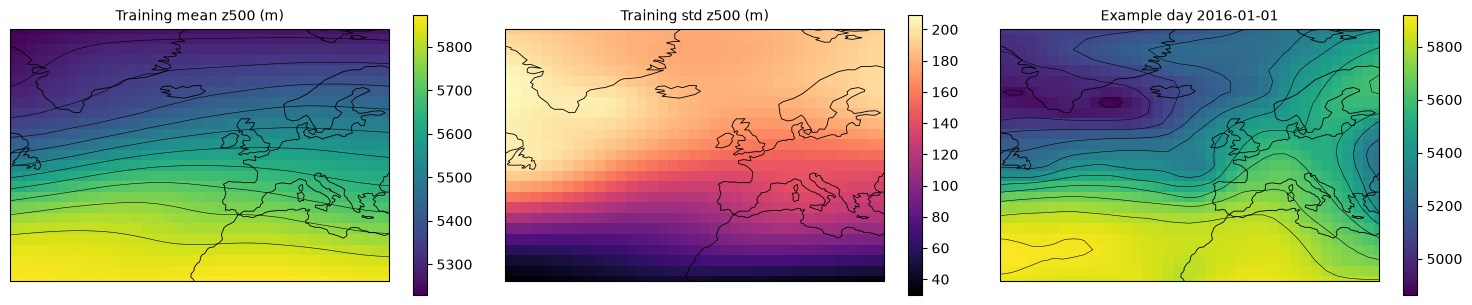

In [6]:
import matplotlib.pyplot as plt

try:
    import cartopy.crs as ccrs
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False

def map_axes(fig, nrows, ncols, idx):
    if HAS_CARTOPY:
        ax = fig.add_subplot(nrows, ncols, idx, projection=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.6, color="k")
        ax.set_extent([LONS.min(), LONS.max(), LATS.min(), LATS.max()], crs=ccrs.PlateCarree())
    else:
        ax = fig.add_subplot(nrows, ncols, idx)
        ax.set_xlabel("lon"); ax.set_ylabel("lat")
    return ax

def plot_field(ax, field, title, cmap="viridis", vmin=None, vmax=None, contours=True):
    kw = dict(transform=ccrs.PlateCarree()) if HAS_CARTOPY else {}
    im = ax.pcolormesh(LONS, LATS, field, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto", **kw)
    if contours:
        ax.contour(LONS, LATS, field, levels=10, colors="k", linewidths=0.4, **kw)
    ax.set_title(title, fontsize=10)
    return im

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

fig = plt.figure(figsize=(15, 3.8))
for i, (field, title, cmap) in enumerate([
        (MU, "Training mean z500 (m)", "viridis"),
        (SD, "Training std z500 (m)", "magma"),
        (z_test.isel(time=0).values, f"Example day {dates_test[0]:%Y-%m-%d}", "viridis")]):
    ax = map_axes(fig, 1, 3, i + 1)
    fig.colorbar(plot_field(ax, field, title, cmap, contours=(i != 1)), ax=ax, shrink=0.8)
plt.tight_layout(); savefig(fig, "01_data_overview"); plt.show()

## 4 · Evaluation metrics

All metrics are computed on the **test set (2016–2022)** in physical units, after undoing the standardisation, and are **area-weighted by cos(latitude)** (grid boxes shrink towards the pole).

* **RMSE / MAE** in metres of geopotential height.
* **ACC** (anomaly correlation coefficient): spatial correlation between the true and reconstructed *anomalies* relative to the monthly climatology. This is the standard weather-forecast skill score. Raw field correlation is almost always > 0.99 for z500 because of the large north–south gradient, so it says little on its own; it is reported as `corr` for completeness.

In [7]:
WLAT = np.cos(np.deg2rad(LATS))[:, None] * np.ones((1, W))
WLAT = (WLAT / WLAT.mean()).astype("float32")                      # mean weight = 1

def to_metres(Xn):
    return Xn * SD + MU

def per_sample_scores(X_true_n, X_rec_n, months):
    t, r = to_metres(X_true_n), to_metres(X_rec_n)
    err = r - t
    rmse = np.sqrt((WLAT * err**2).mean(axis=(1, 2)))
    mae = (WLAT * np.abs(err)).mean(axis=(1, 2))
    clim = CLIM[months - 1]
    def wcorr(a, b):
        a = a - (WLAT * a).mean(axis=(1, 2), keepdims=True)
        b = b - (WLAT * b).mean(axis=(1, 2), keepdims=True)
        return (WLAT * a * b).sum((1, 2)) / np.sqrt((WLAT * a**2).sum((1, 2)) * (WLAT * b**2).sum((1, 2)))
    acc = wcorr(t - clim, r - clim)
    corr = wcorr(t, r)
    return pd.DataFrame({"rmse_m": rmse, "mae_m": mae, "acc": acc, "corr": corr})

def evaluate(X_true_n, X_rec_n, months):
    s = per_sample_scores(X_true_n, X_rec_n, months)
    err = to_metres(X_rec_n) - to_metres(X_true_n)
    return {
        "rmse_m": float(np.sqrt((WLAT * err**2).mean())),
        "mae_m": float((WLAT * np.abs(err)).mean()),
        "acc": float(s["acc"].mean()),
        "corr": float(s["corr"].mean()),
    }

## 5 · Baseline: PCA

PCA is fitted once on the training set; using the first *k* components of that fit is identical to fitting PCA with *k* components.

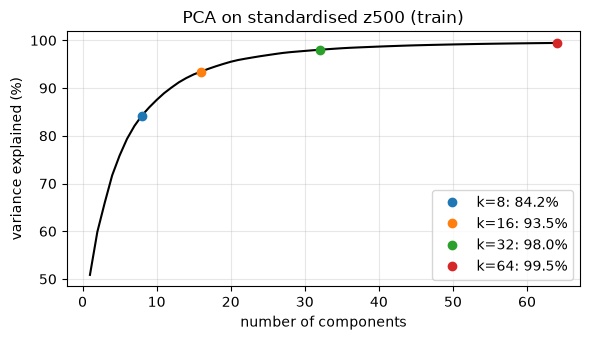

In [8]:
import time
from sklearn.decomposition import PCA

t0 = time.time()
pca = PCA(n_components=max(LATENT_DIMS), random_state=SEED).fit(X_train.reshape(len(X_train), -1))
PCA_FIT_TIME = time.time() - t0

def pca_encode(X, k):
    return (X.reshape(len(X), -1) - pca.mean_) @ pca.components_[:k].T

def pca_reconstruct(X, k):
    Z = pca_encode(X, k)
    return (Z @ pca.components_[:k] + pca.mean_).reshape(X.shape).astype("float32")

cum = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(cum) + 1), cum * 100, "k-")
for k in LATENT_DIMS:
    ax.plot(k, cum[k - 1] * 100, "o", label=f"k={k}: {cum[k-1]*100:.1f}%")
ax.set(xlabel="number of components", ylabel="variance explained (%)", title="PCA on standardised z500 (train)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); savefig(fig, "02_pca_variance"); plt.show()

## 6 · PyTorch setup (ROCm / CUDA / CPU)

PyTorch-ROCm exposes AMD GPUs through the `torch.cuda` API, so the device is still called `"cuda"`. If this prints *CPU* on an AMD machine, check that the ROCm wheel is installed (`torch.version.hip` should not be `None`). The cell also runs a tiny operation on the GPU so that an unsupported-GPU error shows up here, with a clear message, rather than in the middle of training.

If you change `GFX_OVERRIDE` after a GPU error, **restart the kernel** before re-running: the override is only read when the GPU is first initialised.

In [9]:
import math, json, random, time
import torch
import torch.nn as nn
import torch.nn.functional as F

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

if torch.cuda.is_available():
    device = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    backend = f"ROCm/HIP {torch.version.hip}" if torch.version.hip else f"CUDA {torch.version.cuda}"
    arch = getattr(props, "gcnArchName", "")
    print(f"GPU: {props.name} {arch} | {backend} | "
          f"HSA_OVERRIDE_GFX_VERSION={os.environ.get('HSA_OVERRIDE_GFX_VERSION')}")
    try:
        torch.randperm(10, device=device); torch.cuda.synchronize()
    except Exception as e:
        raise RuntimeError(
            "The GPU was found but PyTorch cannot run kernels on it. Set GFX_OVERRIDE in the "
            "config cell (11.0.0 for Radeon 780M/880M/890M and RX 7000, 10.3.0 for RX 6000), "
            "then RESTART THE KERNEL and run all cells again.") from e
else:
    device = torch.device("cpu")
    print("No GPU found, running on CPU (works, but training will be slow)")
AMP = USE_AMP and device.type == "cuda" and torch.cuda.is_bf16_supported()
print("torch", torch.__version__, "| bf16 autocast:", AMP)

/opt/amdgpu/share/libdrm/amdgpu.ids: No such file or directory


GPU: AMD Radeon 880M gfx1100 | ROCm/HIP 6.4.43484-123eb5128 | HSA_OVERRIDE_GFX_VERSION=11.0.0
torch 2.9.1+rocm6.4 | bf16 autocast: True


## 7 · Vision Transformer Autoencoder

The map is cut into 4×4-cell patches (7×10 = 70 tokens). Self-attention lets every patch interact with every other patch directly, so the model can link distant regions in one step (e.g. a ridge over Scandinavia and a trough over Iberia). A few learned query tokens then *attention-pool* the patch tokens into the `LATENT_DIM` bottleneck; the decoder has one query per patch position that attends to the latent and predicts that patch's pixels. A final 3×3 conv (initialised as identity) smooths patch seams.

In [10]:
class ViTAutoencoder(nn.Module):
    def __init__(self, H, W, latent_dim=32, patch=4, d_model=128, enc_depth=4, dec_depth=4,
                 n_heads=4, mlp_ratio=4, n_pool_tokens=4, n_mem_tokens=4, dropout=0.1):
        super().__init__()
        self.H, self.W, self.P = H, W, patch
        self.Hp, self.Wp = math.ceil(H / patch) * patch, math.ceil(W / patch) * patch
        self.gh, self.gw = self.Hp // patch, self.Wp // patch
        self.n_patches, self.n_mem, self.d = self.gh * self.gw, n_mem_tokens, d_model

        self.patch_embed = nn.Conv2d(1, d_model, kernel_size=patch, stride=patch)
        self.enc_pos = nn.Parameter(torch.zeros(1, self.n_patches, d_model))
        enc_layer = nn.TransformerEncoderLayer(d_model, n_heads, d_model * mlp_ratio, dropout,
                                               activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, enc_depth, enable_nested_tensor=False)
        self.enc_norm = nn.LayerNorm(d_model)

        self.pool_queries = nn.Parameter(torch.zeros(1, n_pool_tokens, d_model))
        self.pool_attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.to_latent = nn.Linear(n_pool_tokens * d_model, latent_dim)
        self.from_latent = nn.Linear(latent_dim, n_mem_tokens * d_model)

        self.dec_queries = nn.Parameter(torch.zeros(1, self.n_patches, d_model))
        dec_layer = nn.TransformerDecoderLayer(d_model, n_heads, d_model * mlp_ratio, dropout,
                                               activation="gelu", batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(dec_layer, dec_depth)
        self.dec_norm = nn.LayerNorm(d_model)
        self.to_pixels = nn.Linear(d_model, patch * patch)
        self.refine = nn.Conv2d(1, 1, kernel_size=3, padding=1)

        for p in (self.enc_pos, self.dec_queries, self.pool_queries):
            nn.init.trunc_normal_(p, std=0.02)
        nn.init.zeros_(self.refine.weight); nn.init.zeros_(self.refine.bias)
        with torch.no_grad():
            self.refine.weight[0, 0, 1, 1] = 1.0

    def encode(self, x):
        B = x.shape[0]
        x = F.pad(x, (0, self.Wp - self.W, 0, self.Hp - self.H), mode="replicate")
        t = self.patch_embed(x).flatten(2).transpose(1, 2) + self.enc_pos
        t = self.enc_norm(self.encoder(t))
        pooled, _ = self.pool_attn(self.pool_queries.expand(B, -1, -1), t, t)
        return self.to_latent(pooled.flatten(1))

    def decode(self, z):
        B = z.shape[0]
        mem = self.from_latent(z).view(B, self.n_mem, self.d)
        t = self.dec_norm(self.decoder(self.dec_queries.expand(B, -1, -1), mem))
        px = self.to_pixels(t).view(B, self.gh, self.gw, self.P, self.P).permute(0, 1, 3, 2, 4)
        img = self.refine(px.reshape(B, 1, self.Hp, self.Wp))
        return img[:, :, :self.H, :self.W]

    def forward(self, x):
        return self.decode(self.encode(x))

In [11]:
n_params = lambda m: sum(p.numel() for p in m.parameters())
build_model = lambda ld: ViTAutoencoder(H, W, ld)

m = build_model(PLOT_LD)
with torch.no_grad():
    out = m(torch.zeros(2, 1, H, W))
print(f"ViT-AE  params={n_params(m)/1e6:.2f}M  patches={m.gh}x{m.gw}  output shape={tuple(out.shape)}")
del m

ViT-AE  params=1.97M  patches=7x10  output shape=(2, 1, 25, 37)


## 8 · Training utilities

The whole dataset fits in GPU memory (≈60 MB), so batches are sliced directly from a device tensor instead of using a DataLoader. AdamW with linear warm-up and cosine decay; the checkpoint with the lowest validation loss is kept.

In [12]:
def train_model(model, X_tr, X_va, epochs, lr, weight_decay, warmup, label=""):
    model = model.to(device)
    Xtr = torch.tensor(X_tr).unsqueeze(1).to(device)
    Xva = torch.tensor(X_va).unsqueeze(1).to(device)
    steps = len(Xtr) // BATCH_SIZE
    total, warm = epochs * steps, max(1, warmup * steps)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
        else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))

    hist, best, best_state, t0 = {"train": [], "val": []}, float("inf"), None, time.time()
    for ep in range(epochs):
        model.train()
        perm, run = torch.randperm(len(Xtr), device=device), 0.0
        for i in range(steps):
            xb = Xtr[perm[i * BATCH_SIZE:(i + 1) * BATCH_SIZE]]
            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=AMP):
                loss = F.mse_loss(model(xb), xb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            run += loss.item()
        val = F.mse_loss(predict(model, Xva), Xva).item()
        hist["train"].append(run / steps); hist["val"].append(val)
        if val < best:
            best, best_state = val, {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ep % max(1, epochs // 10) == 0 or ep == epochs - 1:
            print(f"  {label} ep {ep:3d}  train {run/steps:.4f}  val {val:.4f}  ({time.time()-t0:.0f}s)")
    model.load_state_dict(best_state)
    hist["time_s"] = time.time() - t0
    return model, hist

@torch.no_grad()
def predict(model, X, bs=512):
    model.eval()
    Xt = X if torch.is_tensor(X) else torch.tensor(X).unsqueeze(1)
    out = [model(Xt[i:i + bs].to(device)).float() for i in range(0, len(Xt), bs)]
    out = torch.cat(out)
    return out if torch.is_tensor(X) else out.squeeze(1).cpu().numpy()

@torch.no_grad()
def get_latents(model, X, bs=512):
    model.eval()
    Xt = torch.tensor(X).unsqueeze(1)
    return torch.cat([model.encode(Xt[i:i + bs].to(device)).float().cpu()
                      for i in range(0, len(Xt), bs)]).numpy()

## 9 · The sweep: latent dim ∈ {8, 16, 32, 64}, PCA vs ViT-AE

Trained weights and loss histories are saved to `outputs/models/`; on re-runs they are loaded instead of retrained. Each latent dim is a separate training run.

In [13]:
METHODS = ["PCA", "ViT-AE"]
results, histories, recons, trained = [], {}, {}, {}

for ld in LATENT_DIMS:
    ratio = H * W / ld
    print(f"\n=== latent dim {ld}  (compression {ratio:.1f}x) ===")

    # --- PCA ---
    rec = pca_reconstruct(X_test, ld)
    recons[("PCA", ld)] = rec
    results.append({"model": "PCA", "latent_dim": ld, "compression": ratio,
                    "params": ld * H * W + H * W, "train_time_s": PCA_FIT_TIME,
                    **evaluate(X_test, rec, months_test)})

    # --- ViT-AE ---
    set_seed(SEED)
    model = build_model(ld)
    ckpt = MODEL_DIR / f"ViT-AE_ld{ld}.pt"
    hfile = MODEL_DIR / f"ViT-AE_ld{ld}_history.json"
    if ckpt.exists() and hfile.exists() and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location="cpu"))
        model.to(device)
        hist = json.loads(hfile.read_text())
        print("  ViT-AE: loaded from cache")
    else:
        model, hist = train_model(model, X_train, X_val, EPOCHS, LR, WEIGHT_DECAY, WARMUP, label="ViT-AE")
        torch.save(model.state_dict(), ckpt)
        hfile.write_text(json.dumps(hist))
    rec = predict(model, X_test)
    recons[("ViT-AE", ld)] = rec
    histories[ld] = hist
    trained[ld] = model
    results.append({"model": "ViT-AE", "latent_dim": ld, "compression": ratio,
                    "params": n_params(model), "train_time_s": hist["time_s"],
                    **evaluate(X_test, rec, months_test)})

df = pd.DataFrame(results)
df.to_csv(OUT_DIR / "results.csv", index=False)
print("\nSaved", OUT_DIR / "results.csv")


=== latent dim 8  (compression 115.6x) ===
  ViT-AE: loaded from cache


/home/akshayprashad/Desktop/fun/AI_weather/Transformer model/.venv/lib/python3.12/site-packages/torch/nn/modules/transformer.py:902: UserWarning: Flash Efficient attention on Current AMD GPU is still experimental. Enable it with TORCH_ROCM_AOTRITON_ENABLE_EXPERIMENTAL=1. (Triggered internally at /pytorch/aten/src/ATen/native/transformers/hip/sdp_utils.cpp:287.)
  return torch._transformer_encoder_layer_fwd(
/home/akshayprashad/Desktop/fun/AI_weather/Transformer model/.venv/lib/python3.12/site-packages/torch/nn/modules/transformer.py:902: UserWarning: Mem Efficient attention on Current AMD GPU is still experimental. Enable it with TORCH_ROCM_AOTRITON_ENABLE_EXPERIMENTAL=1. (Triggered internally at /pytorch/aten/src/ATen/native/transformers/hip/sdp_utils.cpp:338.)
  return torch._transformer_encoder_layer_fwd(



=== latent dim 16  (compression 57.8x) ===
  ViT-AE ep   0  train 0.6896  val 0.4993  (30s)
  ViT-AE ep  10  train 0.2130  val 0.1858  (357s)
  ViT-AE ep  20  train 0.1051  val 0.0921  (698s)
  ViT-AE ep  30  train 0.0745  val 0.0683  (1043s)
  ViT-AE ep  40  train 0.0669  val 0.0618  (1356s)
  ViT-AE ep  50  train 0.0636  val 0.0596  (1696s)
  ViT-AE ep  60  train 0.0612  val 0.0581  (2020s)
  ViT-AE ep  70  train 0.0595  val 0.0575  (2345s)
  ViT-AE ep  80  train 0.0584  val 0.0565  (2664s)
  ViT-AE ep  90  train 0.0577  val 0.0563  (2963s)
  ViT-AE ep  99  train 0.0575  val 0.0563  (3242s)

=== latent dim 32  (compression 28.9x) ===
  ViT-AE ep   0  train 0.7525  val 0.4990  (32s)
  ViT-AE ep  10  train 0.1992  val 0.1756  (358s)
  ViT-AE ep  20  train 0.0889  val 0.0758  (718s)
  ViT-AE ep  30  train 0.0595  val 0.0516  (1079s)
  ViT-AE ep  40  train 0.0482  val 0.0420  (1422s)
  ViT-AE ep  50  train 0.0435  val 0.0378  (1699s)
  ViT-AE ep  60  train 0.0392  val 0.0346  (1963s)
  

## 10 · Results

### 10a · Results table (test set, 2016–2022)

In [14]:
table = df.pivot(index="latent_dim", columns="model", values=["rmse_m", "mae_m", "acc"])
table = table.reindex(columns=METHODS, level=1)
table.insert(0, ("", "compression"), (H * W / table.index.to_numpy()).round(1))
table.style.format("{:.3f}").format("{:.1f}", subset=[("", "compression")]) \
     .highlight_min(subset=["rmse_m", "mae_m"], axis=1, props="font-weight:bold") \
     .highlight_max(subset=["acc"], axis=1, props="font-weight:bold")

In [15]:
pca_rmse = df[df.model == "PCA"].set_index("latent_dim")["rmse_m"]
gain = df[df.model == "ViT-AE"].copy()
gain["RMSE change vs PCA (%)"] = 100 * (gain["rmse_m"] / gain["latent_dim"].map(pca_rmse) - 1)
gain.set_index("latent_dim")[["rmse_m", "RMSE change vs PCA (%)"]].round(2)

,rmse_m,RMSE change vs PCA (%)
latent_dim,,
8,51.20,-4.88
16,32.23,-6.89
32,23.37,19.71
64,22.58,116.00


Negative = ViT-AE is better than PCA. This is the number that answers "does nonlinearity help?".

### 10b · Accuracy vs compression

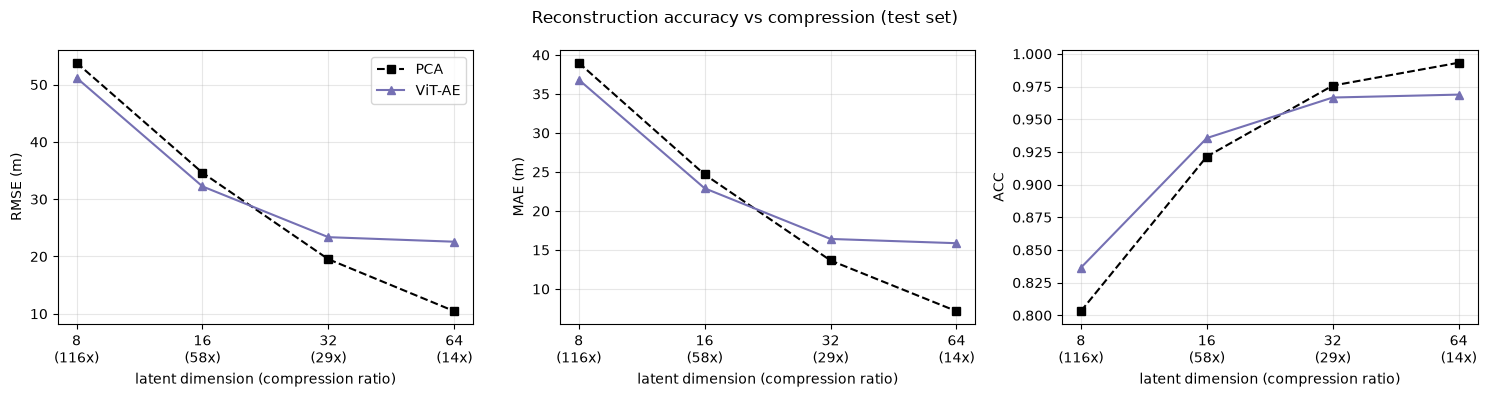

In [16]:
STYLE = {"PCA": dict(color="k", marker="s", ls="--"),
         "ViT-AE": dict(color="#7570b3", marker="^")}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for metric, ax, lab in zip(["rmse_m", "mae_m", "acc"], axes, ["RMSE (m)", "MAE (m)", "ACC"]):
    for name in METHODS:
        d = df[df.model == name].sort_values("latent_dim")
        ax.plot(d.latent_dim, d[metric], label=name, **STYLE[name])
    ax.set_xscale("log", base=2); ax.minorticks_off()
    ax.set_xticks(LATENT_DIMS)
    ax.set_xticklabels([f"{k}\n({H*W/k:.0f}x)" for k in LATENT_DIMS])
    ax.set(xlabel="latent dimension (compression ratio)", ylabel=lab); ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle("Reconstruction accuracy vs compression (test set)")
plt.tight_layout(); savefig(fig, "03_accuracy_vs_compression"); plt.show()

### 10c · Training curves

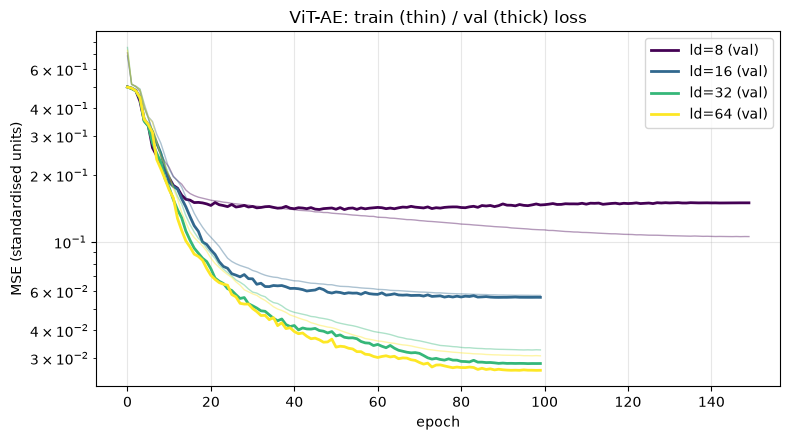

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cmap = plt.get_cmap("viridis")
for i, ld in enumerate(LATENT_DIMS):
    h = histories[ld]
    c = cmap(i / max(1, len(LATENT_DIMS) - 1))
    ax.plot(h["train"], color=c, alpha=0.4, lw=1)
    ax.plot(h["val"], color=c, lw=2, label=f"ld={ld} (val)")
ax.set(yscale="log", xlabel="epoch", ylabel="MSE (standardised units)",
       title="ViT-AE: train (thin) / val (thick) loss")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); savefig(fig, "04_training_curves"); plt.show()

### 10d · Reconstructions: original | PCA | ViT-AE

Top row: full fields. Bottom row: the true anomaly (vs. monthly climatology) and each method's error. One winter and one summer day from the test set.

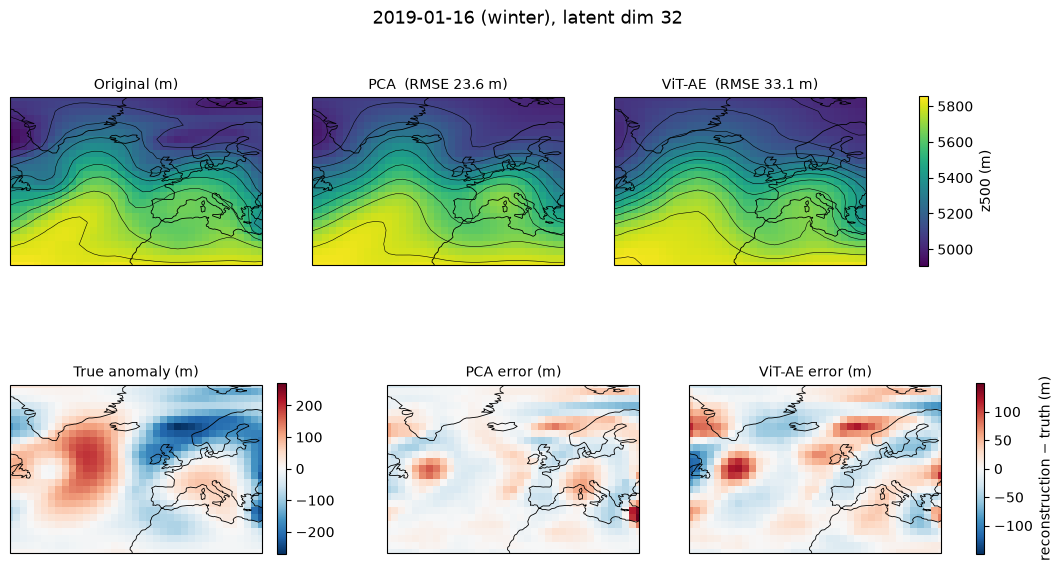

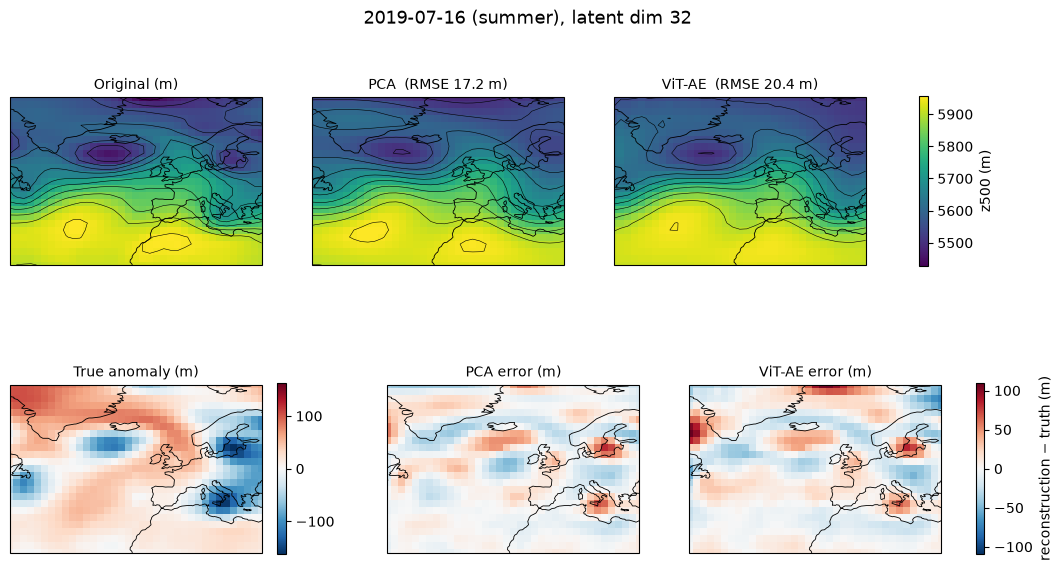

In [18]:
def pick_day(month, offset=0):
    idx = np.where(months_test == month)[0]
    return idx[len(idx) // 2 + offset]

n = len(METHODS) + 1
for tag, i in [("winter", pick_day(1)), ("summer", pick_day(7))]:
    true_m = to_metres(X_test[i])
    recs_m = {m: to_metres(recons[(m, PLOT_LD)][i]) for m in METHODS}
    anom = true_m - CLIM[months_test[i] - 1]
    vmin, vmax = true_m.min(), true_m.max()
    emax = max(np.abs(recs_m[m] - true_m).max() for m in METHODS)
    amax = np.abs(anom).max()

    fig = plt.figure(figsize=(4.6 * n, 6.5))
    top = [map_axes(fig, 2, n, k) for k in range(1, n + 1)]
    bot = [map_axes(fig, 2, n, k) for k in range(n + 1, 2 * n + 1)]
    fig.subplots_adjust(hspace=0.35)
    im = plot_field(top[0], true_m, "Original (m)", vmin=vmin, vmax=vmax)
    for j, m in enumerate(METHODS):
        r = recs_m[m]
        rmse = np.sqrt((WLAT * (r - true_m) ** 2).mean())
        plot_field(top[j + 1], r, f"{m}  (RMSE {rmse:.1f} m)", vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=top, shrink=0.8, label="z500 (m)")
    im2 = plot_field(bot[0], anom, "True anomaly (m)", "RdBu_r", -amax, amax, contours=False)
    fig.colorbar(im2, ax=bot[0], shrink=0.8)
    for j, m in enumerate(METHODS):
        ime = plot_field(bot[j + 1], recs_m[m] - true_m, f"{m} error (m)",
                         "RdBu_r", -emax, emax, contours=False)
    fig.colorbar(ime, ax=bot[1:], shrink=0.8, label="reconstruction − truth (m)")
    fig.suptitle(f"{dates_test[i]:%Y-%m-%d} ({tag}), latent dim {PLOT_LD}", fontsize=13)
    savefig(fig, f"05_reconstruction_{tag}"); plt.show()

### 10e · Where are the errors? (RMSE map over the test set)

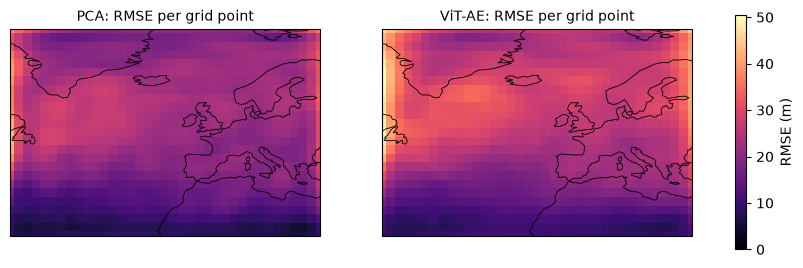

In [19]:
n = len(METHODS)
fig = plt.figure(figsize=(5.5 * n, 3.8))
maps = {m: np.sqrt(((to_metres(recons[(m, PLOT_LD)]) - to_metres(X_test)) ** 2).mean(0)) for m in METHODS}
vmax = max(v.max() for v in maps.values())
for j, m in enumerate(METHODS):
    im = plot_field(map_axes(fig, 1, n, j + 1), maps[m], f"{m}: RMSE per grid point", "magma", 0, vmax, contours=False)
fig.colorbar(im, ax=fig.axes, shrink=0.8, label="RMSE (m)")
savefig(fig, "06_rmse_maps"); plt.show()

### 10f · Error by season

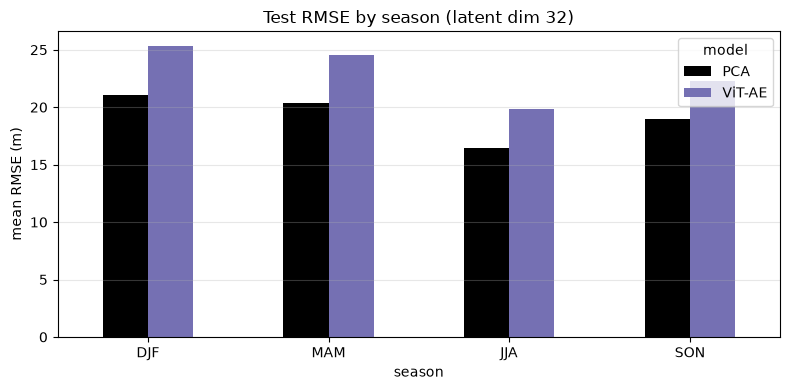

model,PCA,ViT-AE
season,,
DJF,21.020000,25.340000
MAM,20.360001,24.559999
JJA,16.459999,19.809999
SON,19.000000,22.320000


In [20]:
rows = []
for m in METHODS:
    s = per_sample_scores(X_test, recons[(m, PLOT_LD)], months_test)
    s["season"], s["model"] = seasons_test, m
    rows.append(s)
by_season = pd.concat(rows).groupby(["season", "model"])["rmse_m"].mean().unstack()
by_season = by_season.loc[SEASONS, METHODS]

ax = by_season.plot.bar(figsize=(8, 4), color=[STYLE[m]["color"] for m in METHODS], rot=0)
ax.set(ylabel="mean RMSE (m)", title=f"Test RMSE by season (latent dim {PLOT_LD})"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); savefig(ax.figure, "07_rmse_by_season"); plt.show()
by_season.round(2)

## 11 · Latent space

Each test day's latent vector is projected to 2-D (with PCA, for display) and coloured by season. If the model has learned meaningful structure, winter and summer days should separate, because the seasonal cycle is the largest source of variance in z500.

The **silhouette score** (−1…1, higher = cleaner clusters) quantifies how well the full latent vectors separate the four seasons.

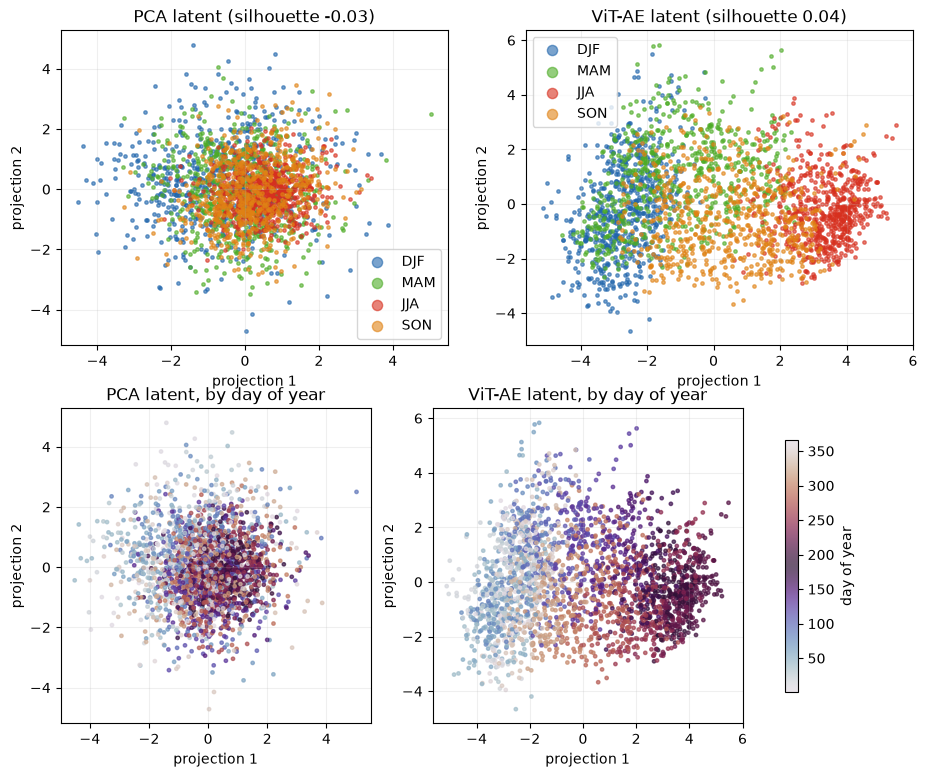

In [21]:
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

latents = {"PCA": pca_encode(X_test, PLOT_LD), "ViT-AE": get_latents(trained[PLOT_LD], X_test)}

n = len(METHODS)
doy = dates_test.dayofyear.values
fig, axes = plt.subplots(2, n, figsize=(5.5 * n, 9), squeeze=False)
for j, m in enumerate(METHODS):
    Zs = StandardScaler().fit_transform(latents[m])
    Z2 = PCA(2, random_state=SEED).fit_transform(Zs)
    sil = silhouette_score(Zs, seasons_test, random_state=SEED)
    ax = axes[0, j]
    for s in SEASONS:
        k = seasons_test == s
        ax.scatter(Z2[k, 0], Z2[k, 1], s=6, alpha=0.6, c=SEASON_COLORS[s], label=s)
    ax.set_title(f"{m} latent (silhouette {sil:.2f})"); ax.legend(markerscale=3)
    sc = axes[1, j].scatter(Z2[:, 0], Z2[:, 1], c=doy, cmap="twilight", s=6, alpha=0.7)
    axes[1, j].set_title(f"{m} latent, by day of year")
    for ax in axes[:, j]:
        ax.set(xlabel="projection 1", ylabel="projection 2"); ax.grid(alpha=0.2)
fig.colorbar(sc, ax=axes[1, :], shrink=0.8, label="day of year")
savefig(fig, "08_latent_space"); plt.show()

## 12 · Summary for the presentation

The cell below writes the key numbers out as sentences you can put on slides; the notes after it are talking points to adapt once you see your results.

In [22]:
print("ViT-AE vs PCA, test set 2016–2022:")
for _, r in gain.iterrows():
    p = pca_rmse[r.latent_dim]
    word = "better" if r["RMSE change vs PCA (%)"] < 0 else "worse"
    print(f"  ld={r.latent_dim:>2} ({H*W/r.latent_dim:5.1f}x): ViT-AE RMSE {r.rmse_m:5.1f} m vs PCA {p:5.1f} m "
          f"-> {abs(r['RMSE change vs PCA (%)']):4.1f}% {word}, ACC {r.acc:.3f}")

d = df[df.model == "ViT-AE"]
print(f"\nTraining cost: {d.params.mean()/1e6:.2f}M params, {d.train_time_s.mean()/60:.1f} min per run on {device}")
print(f"PCA fitted in {PCA_FIT_TIME:.1f} s")

ViT-AE vs PCA, test set 2016–2022:
  ld= 8 (115.6x): ViT-AE RMSE  51.2 m vs PCA  53.8 m ->  4.9% better, ACC 0.836
  ld=16 ( 57.8x): ViT-AE RMSE  32.2 m vs PCA  34.6 m ->  6.9% better, ACC 0.936
  ld=32 ( 28.9x): ViT-AE RMSE  23.4 m vs PCA  19.5 m -> 19.7% worse, ACC 0.967
  ld=64 ( 14.5x): ViT-AE RMSE  22.6 m vs PCA  10.5 m -> 116.0% worse, ACC 0.969

Training cost: 1.97M params, 55.8 min per run on cuda
PCA fitted in 0.3 s
